# Machine Learning Experiment Number 8


**Name:** Om Milind Retharekar   
           
**Roll no.:** CS46

**Class:** BE CSE

**Batch:** CS 03

### **Aim**

To implement graph-based clustering using Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset in Python and visualize the resulting clusters.

## Objectives

1. To understand the concept of graph-based clustering and Minimum Spanning Trees (MST).
2. To load and preprocess the Breast Cancer Wisconsin dataset (scaling features and handling metadata).
3. To construct a distance graph from tumor feature representations using Euclidean distance.
4. To compute the Minimum Spanning Tree using Prim's or Kruskal's algorithm (or via scipy/networkx).
5. To form $K=2$ clusters (Malignant vs. Benign) by removing the single ($K - 1$) largest edge weight from the MST.
6. To evaluate the performance of the MST-based clustering model using evaluation metrics.

# Relevant Theory

###Graph-Based Clustering & Minimum Spanning Tree (MST)
Graph-based clustering represents data points as nodes in a graph, with edges representing relationships or distance metrics between individual samples.
* **Complete Graph Construction**: Given a dataset $X = \{x_1, x_2, \dots, x_n\}$,
each tissue sample is treated as a vertex. An edge weight $w(i, j)$ corresponds to the distance between sample $i$ and sample $j$ (typically Euclidean distance on scaled features):$$w(i, j) = \Vert{}x_i - x_j\Vert{}_2$$
* **Minimum Spanning Tree (MST)**: An MST is a subset of edges connecting all vertices in the graph without forming any cycles, while minimizing the total edge weight sum.
* **MST-Based Clustering Method**:
  1. Construct a fully connected graph with pairwise edge weights across standardized features.
  2. Compute the Minimum Spanning Tree (MST).
  3. To partition the data into $K$ distinct clusters (such as Malignant and Benign groups), identify and remove the $K - 1$ largest (most expensive) edges from the MST.4. The resulting disconnected subgraphs represent the separate data clusters.
### Dataset Information
Get the Breast Cancer Wisconsin (Diagnostic) dataset from Kaggle or via scikit-learn (load_breast_cancer).
The dataset contains key cell nuclei features computed from digitized images of fine needle aspirates (FNA) of breast masses:
  * Total Instances: 569 samples
  * Target Classes: Malignant (M) and Benign (B)* Feature Attributes: 30 numerical features (e.g., mean radius, mean texture, mean perimeter, mean area, mean smoothness)

For 2D visualization, two key features (such as mean radius and mean texture) will be selected.

# Task 1: Import Libraries and Load Dataset

* Import required libraries (numpy, pandas, matplotlib, scipy, networkx, sklearn).

* Load the Breast Cancer dataset using below link from Kaggle.

  https://www.kaggle.com/datasets/utkarshx27/breast-cancer-wisconsin-diagnostic-dataset

---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import networkx as nx
import sklearn

df = pd.read_csv('/content/brca.csv')
df.head()

,Unnamed: 0,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,...,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst,y
0,1,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,...,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259,B
1,2,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,...,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183,B
2,3,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,...,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773,B
3,4,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,...,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169,B
4,5,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,...,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409,B


# Task 2: Explore the Dataset

* Display missing value checks, summary statistics, and feature dimensions.

* Check the diagnosis class distribution (Malignant vs. Benign).

In [2]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Display summary statistics
print("\nSummary Statistics:")
print(df.describe())

# Display feature dimensions
print("\nFeature Dimensions:")
print(df.shape)

# Check diagnosis class distribution
print("\nDiagnosis Class Distribution:")
print(df['y'].value_counts())

Missing Values:
Unnamed: 0             0
x.radius_mean          0
x.texture_mean         0
x.perimeter_mean       0
x.area_mean            0
x.smoothness_mean      0
x.compactness_mean     0
x.concavity_mean       0
x.concave_pts_mean     0
x.symmetry_mean        0
x.fractal_dim_mean     0
x.radius_se            0
x.texture_se           0
x.perimeter_se         0
x.area_se              0
x.smoothness_se        0
x.compactness_se       0
x.concavity_se         0
x.concave_pts_se       0
x.symmetry_se          0
x.fractal_dim_se       0
x.radius_worst         0
x.texture_worst        0
x.perimeter_worst      0
x.area_worst           0
x.smoothness_worst     0
x.compactness_worst    0
x.concavity_worst      0
x.concave_pts_worst    0
x.symmetry_worst       0
x.fractal_dim_worst    0
y                      0
dtype: int64

Summary Statistics:
       Unnamed: 0  x.radius_mean  x.texture_mean  x.perimeter_mean  \
count  569.000000     569.000000      569.000000        569.000000   
mean   285

# Task 3: Preprocess and Scale Features

* Select numerical features and drop non-informative identifiers (such as id).

* Apply StandardScaler to normalize feature magnitudes prior to graph distance calculation.

In [3]:
from sklearn.preprocessing import StandardScaler

# Select numerical features and remove non-informative identifier
X = df.drop(columns=['Unnamed: 0', 'y'])

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Task 4: Construct Pairwise Distance Matrix & Graph

* Compute pairwise Euclidean distance matrix across all scaled samples using scipy.spatial.distance.pdist or cdist.

* Represent the dataset as a weighted complete graph.

In [4]:
from scipy.spatial.distance import pdist, squareform
import networkx as nx

# Compute pairwise Euclidean distance matrix
distance_matrix = squareform(pdist(X_scaled, metric='euclidean'))

# Construct weighted complete graph
G = nx.from_numpy_array(distance_matrix)

# Task 5: Compute the Minimum Spanning Tree (MST)

* Compute the MST using scipy.sparse.csgraph.minimum_spanning_tree or networkx.minimum_spanning_tree.

* Extract the resulting graph connections and weights.

In [5]:
from scipy.sparse.csgraph import minimum_spanning_tree

# Compute the Minimum Spanning Tree
mst = minimum_spanning_tree(distance_matrix)

# Extract MST connections and weights
mst_connections = []

rows, cols = mst.nonzero()

for i, j in zip(rows, cols):
    mst_connections.append((i, j, mst[i, j]))

mst_connections[:10]

[(np.int32(0), np.int32(81), np.float64(1.688589884751502)),
 (np.int32(0), np.int32(108), np.float64(2.1714476618283567)),
 (np.int32(1), np.int32(105), np.float64(1.6607267131218872)),
 (np.int32(2), np.int32(70), np.float64(2.218949334515698)),
 (np.int32(3), np.int32(170), np.float64(2.346213328330311)),
 (np.int32(3), np.int32(222), np.float64(2.5415242027912224)),
 (np.int32(4), np.int32(84), np.float64(2.166020221845041)),
 (np.int32(4), np.int32(279), np.float64(1.8603236849319482)),
 (np.int32(5), np.int32(125), np.float64(1.7658726578704034)),
 (np.int32(5), np.int32(172), np.float64(2.0170999016357793))]

# Task 6: Implement Graph-Based Clustering ($K=2$)

* Sort the edges of the MST in descending order by edge weight.
* Remove the largest $K - 1$ edge (1 largest edge for 2 clusters) to split the MST into 2 connected components.
* Assign final cluster labels based on the resulting component indices.


In [6]:
# Sort MST edges in descending order by edge weight
edges = sorted(mst_connections, key=lambda x: x[2], reverse=True)

# Remove the largest edge to form 2 clusters
mst_graph = nx.Graph()
mst_graph.add_nodes_from(range(len(X_scaled)))
mst_graph.add_weighted_edges_from(edges[1:])

# Find the two connected components
components = list(nx.connected_components(mst_graph))

# Assign cluster labels based on component indices
cluster_labels = np.zeros(len(X_scaled), dtype=int)

for cluster_id, component in enumerate(components):
    for sample in component:
        cluster_labels[sample] = cluster_id

# Task 7: valuate MST Clustering Performance

Evaluate cluster assignment against ground truth labels using:

  *  Silhouette Score

  *  Adjusted Rand Index (ARI)

  *  Normalized Mutual Information (NMI)

In [8]:
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

# Get the ground truth diagnosis labels
true_labels = df['y'].map({'B': 0, 'M': 1}).values

# Calculate evaluation metrics
silhouette = silhouette_score(X_scaled, cluster_labels)
ari = adjusted_rand_score(true_labels, cluster_labels)
nmi = normalized_mutual_info_score(true_labels, cluster_labels)

print("Silhouette Score:", silhouette)
print("Adjusted Rand Index (ARI):", ari)
print("Normalized Mutual Information (NMI):", nmi)

Silhouette Score: 0.6606668813897673
Adjusted Rand Index (ARI): 0.0048283446965917305
Normalized Mutual Information (NMI): 0.010182219220269649


# Task 8: Visualize MST and Graph-Based Clusters

* Select two representative features (e.g., mean radius vs. mean texture) for 2D plotting.
 * Plot 1: Unclustered standardized data points.
* Plot 2: Minimum Spanning Tree (MST) edge connections overlaid on the data.
* Plot 3: Final clusters formed after cutting the $K - 1$ largest edge(s).

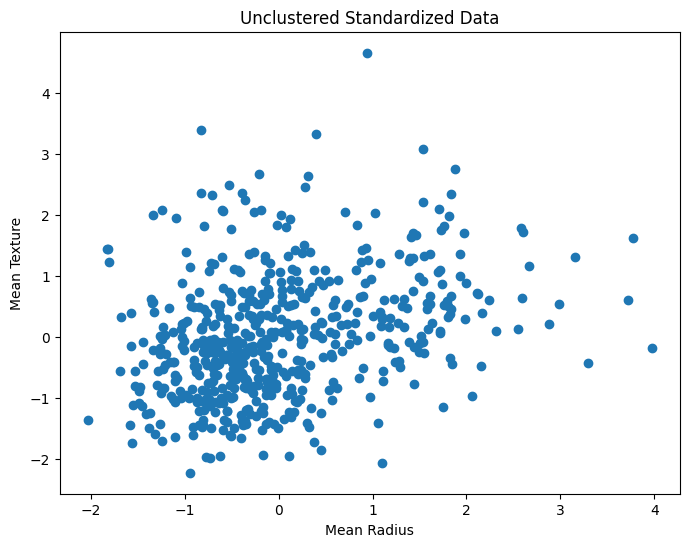

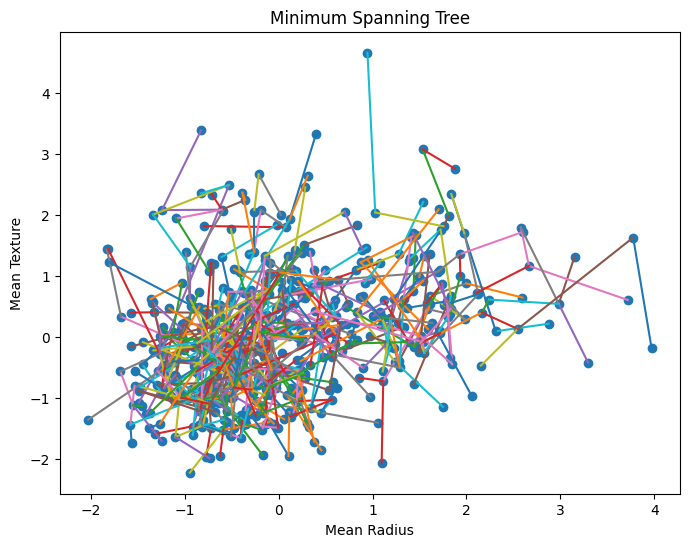

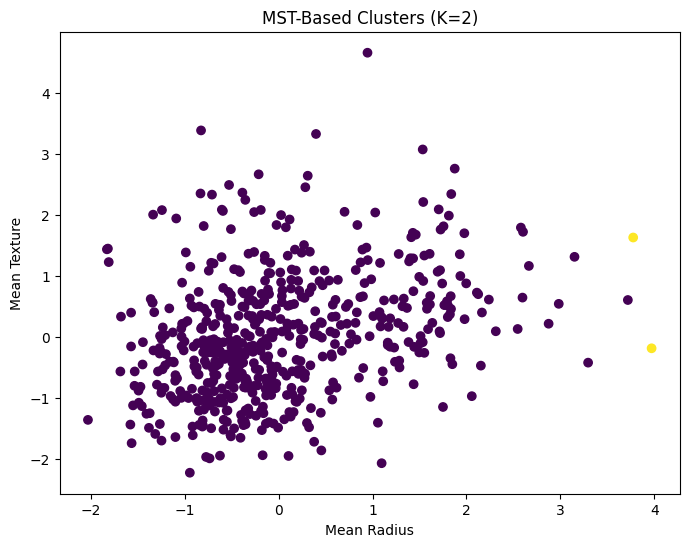

In [9]:
# Select mean radius and mean texture from the standardized features
radius_idx = df.columns.get_loc('x.radius_mean') - 1
texture_idx = df.columns.get_loc('x.texture_mean') - 1

X_2d = X_scaled[:, [radius_idx, texture_idx]]

# Plot 1: Unclustered standardized data points
plt.figure(figsize=(8, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1])
plt.xlabel('Mean Radius')
plt.ylabel('Mean Texture')
plt.title('Unclustered Standardized Data')
plt.show()

# Plot 2: MST edge connections overlaid on the data
plt.figure(figsize=(8, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1])

for i, j, weight in mst_connections:
    plt.plot([X_2d[i, 0], X_2d[j, 0]],
             [X_2d[i, 1], X_2d[j, 1]])

plt.xlabel('Mean Radius')
plt.ylabel('Mean Texture')
plt.title('Minimum Spanning Tree')
plt.show()

# Plot 3: Final clusters after removing the largest MST edge
plt.figure(figsize=(8, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=cluster_labels)
plt.xlabel('Mean Radius')
plt.ylabel('Mean Texture')
plt.title('MST-Based Clusters (K=2)')
plt.show()

# Conclusion

The experiment successfully demonstrated the implementation of Graph-Based Clustering using a Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset. The dataset was preprocessed, cleaned, and standardized before computing pairwise distances. The MST was generated, and by removing the largest edge(s), clusters representing tumor categories were obtained, evaluated using clustering metrics, and visualized.